In [1]:
# Install the seawater library if not already present in your environment:
# !pip install seawater

import seawater as sw  # EOS-80 formulations for seawater properties
import numpy as np
import matplotlib.pyplot as plt



C:\Users\m_pas\AppData\Local\Temp\ipykernel_9160\4089025314.py:4: UserWarning: The seawater library is deprecated! Please use gsw instead.
  import seawater as sw  # EOS-80 formulations for seawater properties


In [2]:
# Load the T-S profiles from the CSV file.
# Inspect the file structure to identify the correct columns for each variable.

# Open and load the dataset
data = np.loadtxt('2TS-profiles_python.csv', delimiter=',', skiprows=2)

p       = data[:, 0] # Pressure axis [dbar]
temp_A  = data[:, 1] # In-situ Temperature at Station A [°C]
sal_A   = data[:, 2] # Practical Salinity at Station A [psu]
temp_B  = data[:, 3] # In-situ Temperature at Station B [°C]
sal_B   = data[:, 4] # Practical Salinity at Station B [psu]

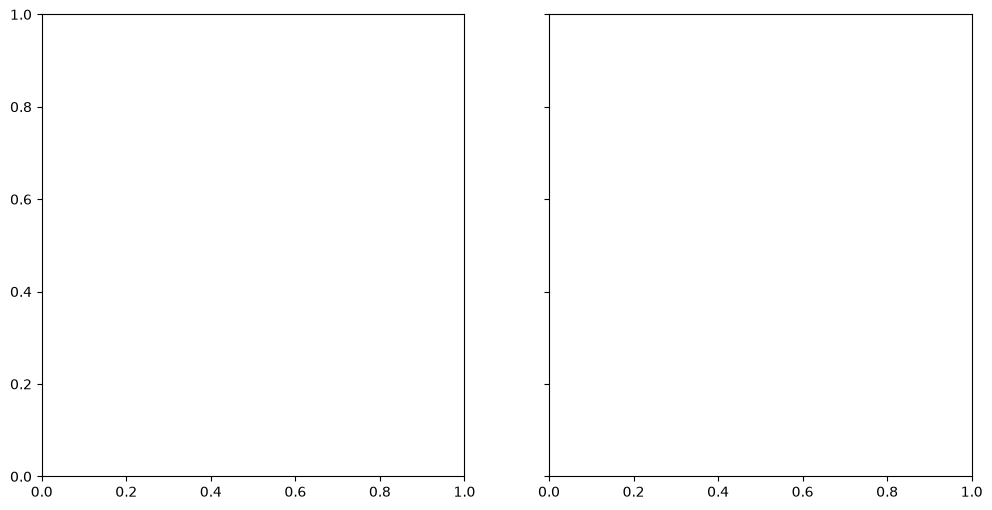

In [3]:
# VISUALIZATION: Plot Temperature and Salinity profiles to observe the initial state.
# Invert the Y-axis to represent depth/pressure from surface to bottom.

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6), sharey=True)


In [4]:

# Left Subplot: Temperature
ax1.plot(temp_A, p, color='blue', label='Station A')
ax1.plot(temp_B, p, color='red', label='Station B')
ax1.set_title("Temperature Profiles")
ax1.set_xlabel("Temperature [°C]")
ax1.set_ylabel("Pressure [dbar]")
ax1.invert_yaxis() # Oceanographic convention
ax1.legend()
ax1.grid(True, linestyle='--')

# Right Subplot: Salinity
ax2.plot(sal_A, p, color='blue', label='Station A')
ax2.plot(sal_B, p, color='red', label='Station B')
ax2.set_title("Salinity Profiles")
ax2.set_xlabel("Salinity [psu]")
ax2.invert_yaxis()
ax2.legend()
ax2.grid(True, linestyle='--')

plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

In [5]:
# EXERCISE: Compute the Specific Volume Anomaly (\delta) for both stations.
# Recall that: \delta = \alpha(S, T, p) - \alpha(35, 0, p)
# where \alpha (specific volume) is the reciprocal of density (\alpha = 1 / \rho).

# HINT: Density depends on Salinity, Temperature, and Pressure in that exact order: rho = f(S, T, p).
# For the real profiles, pass your station variables. For the standard reference, freeze S at 35 and T at 0.

# Step 1: Compute In-situ Density (\rho) using the UNESCO 1983 polynomial (EOS-80)
rho_A = sw.dens(sal_A, temp_A, p)
rho_B = sw.dens(sal_B, temp_B, p)

# Step 2: Compute Standard Ocean Density (\rho_35_0) at Standard Salinity (35 psu) and Temperature (0 °C)
rho_35_0 = sw.dens(35, 0, p)

# Step 3: Convert density to specific volume (\alpha = 1 / \rho)
alpha_A    = 1 / rho_A
alpha_B    = 1 / rho_B
alpha_35_0 = 1 / rho_35_0

# Step 4: Calculate the Anomalies
delta_A = alpha_A - alpha_35_0
delta_B = alpha_B - alpha_35_0

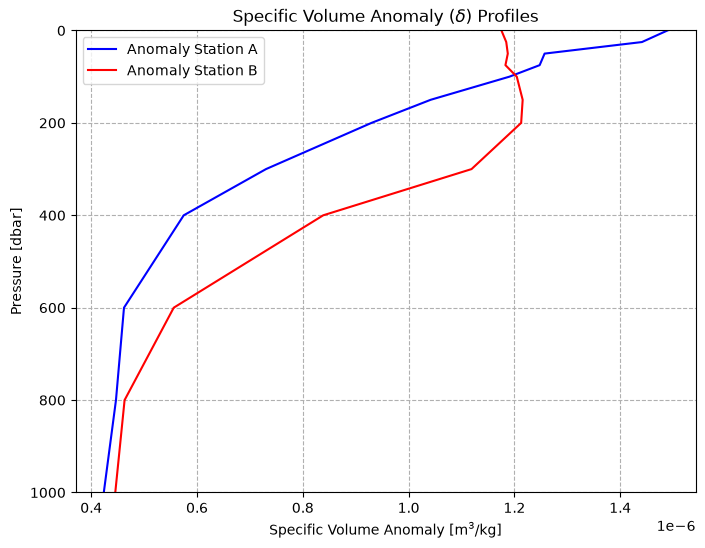

In [6]:
# VISUALIZATION: Plot the Specific Volume Anomaly profiles.
# This helps identify which layers contribute the most to the geopotential differences.

fig = plt.figure(figsize=(8, 6))
plt.plot(delta_A, p, color='blue', label='Anomaly Station A')
plt.plot(delta_B, p, color='red', label='Anomaly Station B')
plt.title(r"Specific Volume Anomaly ($\delta$) Profiles")
plt.xlabel(r"Specific Volume Anomaly [$\mathrm{m^3/kg}$]")
plt.ylabel("Pressure [dbar]")
plt.ylim(np.max(p), np.min(p))
plt.legend()
plt.grid(True, linestyle='--')
plt.show()

In [7]:
# EXERCISE: Integrate the specific volume anomalies along the water column 
# to find the total Geopotential Anomaly (\Delta \Phi = \int \delta \cdot dp).

# Step 1: Calculate hydrostatic pressure increments (dp) and convert from dbar to Pascal (1 dbar = 10000 Pa)
dp = np.diff(p) * 10000 

# Step 2: Calculate the mean \delta within each layer (midpoint rule for trapezoidal integration)
delta_A_mid = (delta_A[:-1] + delta_A[1:]) / 2
delta_B_mid = (delta_B[:-1] + delta_B[1:]) / 2

# Step 3: Compute the geopotential increments (dPot = \delta * dp) for each layer
A_dPot_layers = delta_A_mid * dp
B_dPot_layers = delta_B_mid * dp

# Step 4: Sum all layers to find the cumulative Geopotential Anomaly at the surface relative to the bottom
A_Pot_Total = np.sum(A_dPot_layers)
B_Pot_Total = np.sum(B_dPot_layers)

print(f"Total Geopotential Anomaly (Station A): {A_Pot_Total:.4f} m^2/s^2")
print(f"Total Geopotential Anomaly (Station B): {B_Pot_Total:.4f} m^2/s^2")

Total Geopotential Anomaly (Station A): 6.6710 m^2/s^2
Total Geopotential Anomaly (Station B): 7.8650 m^2/s^2


In [ ]:
# EXERCISE: Convert the Geopotential Anomaly from spatial energy units [m^2/s^2] 
# to Dynamic/Steric Height [dynamic meters] by dividing by standard gravity (g = 9.81 m/s^2).

g = 9.81  # Standard gravity acceleration [m/s^2]

ADynHeight = A_Pot_Total / g
BDynHeight = B_Pot_Total / g

print(f"Steric/Dynamic Height (Station A): {ADynHeight:.4f} m")
print(f"Steric/Dynamic Height (Station B): {BDynHeight:.4f} m")

# FINAL TASK: Compute the relative difference in Sea Surface Topography between the two locations.
# This baroclinic difference drives the geostrophic surface currents between Station A and B!
delta_D = ADynHeight - BDynHeight
print(rf"Relative Dynamic Height Difference (ΔD): {delta_D:.4f} m")

Steric/Dynamic Height (Station A): 0.6800 m
Steric/Dynamic Height (Station B): 0.8017 m
Relative Dynamic Topography Difference (ΔD): -0.1217 m
